## How the Two Pegasus Bounds Work: Per-Node Union Bound and SNC

The evaluation (`2a_base_case.ipynb` to `2e_iterative.ipynb`) reports two versions of Pegasus. Both answer the same question for a chain of
services: **which latency $d$ is exceeded by at most a share $\varepsilon$ of the items?** Both get the same input, the
execution time of every service on its own, and differ only in how they put the services together:

- **Pegasus per node:** bound the latency of every service separately, then add the bounds (union bound).
- **Pegasus SNC:** bound the latency of the whole chain in one step (stochastic network calculus, SNC).

This notebook explains the math behind both from the ground up and then tests, one property at a time, where each one
is strong and where it is weak.

1. **One queue:** where latency comes from when a service is fast enough on average.
2. **The shared tool:** the moment generating function, and the one number per service that sets how fast the tail of
   its waiting time falls.
3. **Bounding one service:** the two ways to turn that tool into a latency bound. One of them is the building block of
   each version.
4. **Bounding a chain:** the two compositions, i.e. the two versions of Pegasus.
5. **Strengths and weaknesses,** tested: the depth of the chain, dependent services, bursty arrivals.
6. **Summary:** which version fits which situation.

**Setting of every section.** Items enter the first service of a chain and pass through the services one after the
other. Every service handles one item at a time, in the order of arrival (FIFO). The services are generated by the
service generator of the evaluation (`synthetic_service` in `pegasus/data.py`), at one fixed configuration, and the
bounds get their true mean and standard deviation. In the evaluation these two numbers come from a GP per service;
here they are known, so that every difference between a bound and the measured latency comes from the bound itself and
not from a model. The setup cell below holds the parameters and prints the three services used in Sections 1 to 4.

**Notation.** Every symbol is defined again where it is first used.
- $\lambda$: arrival rate, items per second. $T$: gap between two consecutive arrivals, in seconds.
- $Y$: execution time of an item at a service, in seconds, as in the paper (the output of the GP). $m$ and $\sigma$: its
  mean and standard deviation. $\mu = 1/m$: service rate, items per second. $\rho = \lambda/\mu$: utilization.
- $W$: waiting time of an item in the queue of a service, in seconds, as in queueing theory.
- $L = W + Y$: latency of an item at a service, and $L$ without index also the end-to-end latency of a chain. Network
  calculus calls this quantity the delay and often writes it $W$; here $W$ is always the waiting time alone.
- $d$: a latency bound. $\varepsilon$: violation probability, the share of items that may exceed $d$.
- $\theta$: free parameter of a moment generating function, in 1/s. $\varphi(\theta)$ and $\theta^*$: Section 2.
- $K$: number of services of a chain; an index $k$ marks the service.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

from pegasus.data import synthetic_chain, synthetic_service, true_demand
from pegasus.bounds import (THETA_GRID, log_interarrival_mgf, martingale_closed_form_node_bound, martingale_closed_form_node_bounds,
                            martingale_theta, network_bound_terms, network_service_bound, snc_latency_bound)
from pegasus.simulation import simulate_chain

plt.style.use("default")
plt.rcParams.update({"font.size": 12})

arrival_rate = 4.0                                    # items/s that enter the first service
arrivals = dict(process="poisson", rate=arrival_rate)  # the arrival process of Sections 1 to 5b
epsilon = 0.05                                        # violation probability: the bound may be exceeded by this share of the items
epsilons = np.array([0.5, 0.3, 0.2, 0.1, 0.05, 0.02, 0.01, 0.005, 0.002, 0.001])   # violation probabilities of the curves over epsilon
configuration = np.array([[0.7, 1.5, 1.0]])           # CPU, quality, parallelism: one configuration, the same for every service
service_seed = 0                                      # seed of the generated service types
replications, n_items = 20, 20_000                    # every simulation: this many independent runs of this many items each
seed = 35                                             # seed of the simulations
ms = lambda seconds: f"{1e3 * seconds:.0f} ms"
p_label = f"p{100 * (1 - epsilon):g}"


def chain_parameters(depth):
    # Mean and standard deviation (s) of the execution time of the services s1 ... s<depth> at `configuration`
    services = [synthetic_service(name, service_seed) for name in synthetic_chain(depth)]
    return np.array([true_demand(configuration, service)[0] for service in services]), np.array([service["noise"] for service in services])


def beliefs_of(means, sds):
    # the input format of the bounds: one (mean, variance) pair per service, each an array with one entry per configuration
    return [(np.array([mean]), np.array([sd ** 2])) for mean, sd in zip(means, sds)]


def simulate(means, sds, rng, item_correlation=0.0, **arrival_process):
    # Latency (s) of every simulated item: per service (items, services), and end to end (items,)
    per_service, end_to_end = simulate_chain(np.tile(means, (replications, 1)), sds, n_items=n_items, item_correlation=item_correlation, rng=rng,
                                             **arrival_process)
    return per_service.reshape(-1, len(means)), end_to_end.ravel()


means3, sds3 = chain_parameters(3)
K3 = len(means3)
print(f"Arrivals: {arrivals['process']}, {arrival_rate:g} items/s, i.e. a mean gap of {ms(1 / arrival_rate)} between two items.")
for k, (mean, sd) in enumerate(zip(means3, sds3), start=1):
    print(f"s{k}: execution time {ms(mean)} on average (service rate {1 / mean:.1f} items/s), standard deviation {1e3 * sd:.1f} ms, utilization {arrival_rate * mean:.0%}")

Arrivals: poisson, 4 items/s, i.e. a mean gap of 250 ms between two items.
s1: execution time 119 ms on average (service rate 8.4 items/s), standard deviation 1.3 ms, utilization 48%
s2: execution time 96 ms on average (service rate 10.4 items/s), standard deviation 1.6 ms, utilization 39%
s3: execution time 104 ms on average (service rate 9.6 items/s), standard deviation 2.5 ms, utilization 42%


## 1. One Queue: Where Latency Comes From

Take the first service alone. Three quantities describe what happens to an item:

- $Y$, the **execution time** of the item: how long the service works on it, in seconds. It varies a little from item
  to item, with mean $m$ and standard deviation $\sigma$ (printed above). The *service rate* $\mu = 1/m$ is the number of
  items per second that the service can handle when it never idles.
- $T$, the **gap**: the time between the arrival of the item before and the arrival of this item, in seconds. With
  the arrival rate $\lambda$ (items per second), the mean gap is $1/\lambda$.
- $W$, the **waiting time**: how long the item waits because the service is still busy with earlier items, in seconds.

The **latency** of the item is $L = W + Y$, waiting plus its own execution.

**The service is fast enough on average.** The *utilization* $\rho = \lambda / \mu = \lambda m$ is the share of time the
service is busy; it is printed above and lies well below 100%. On average an item is finished long before the next one arrives.

**Items still wait, because arrivals are irregular.** Poisson arrivals mean that the gaps are random: most are close
to the mean, some are very short. An example with round numbers: if an item needs 100 ms and the next item arrives
only 40 ms after it, the next item waits 60 ms. If a third item arrives 30 ms later, it waits for the rest of the
first item and for the whole second one. In general (Lindley's recursion):

$$W_i = \max\bigl(0,\; W_{i-1} + Y_{i-1} - T_i\bigr).$$

In words: the waiting time of item $i$ is what item $i-1$ had to wait, plus the execution time of item $i-1$, minus the
gap $T_i$ during which the service could work that off; it cannot be negative. Applying the rule again and again
shows that the waiting time is the largest value of a running sum:

$$W = \max_{n \ge 0}\; \sum_{i=1}^{n} (Y_i - T_i).$$

The sum over the last $n$ items is the work that these items brought minus the time the service had for it. Every term
$Y_i - T_i$ is negative on average (the service is fast enough), so the running sum drifts down, but a run of short
gaps pushes it up for a while. **The whole problem is to bound how high this running sum can get.**

The figure below shows this for the first service. *Left:* the latency (ms, vertical axis) of consecutive items
(horizontal axis); the dashed line is the mean execution time, so everything above it is waiting. *Right:* the
distribution of the latency over all simulated items (horizontal axis: latency in ms; vertical axis: density,
logarithmic so that the rare long latencies stay visible), with the mean execution time and the measured percentile
that the bounds have to stay above. On a logarithmic axis a straight falling line is an exponential tail.

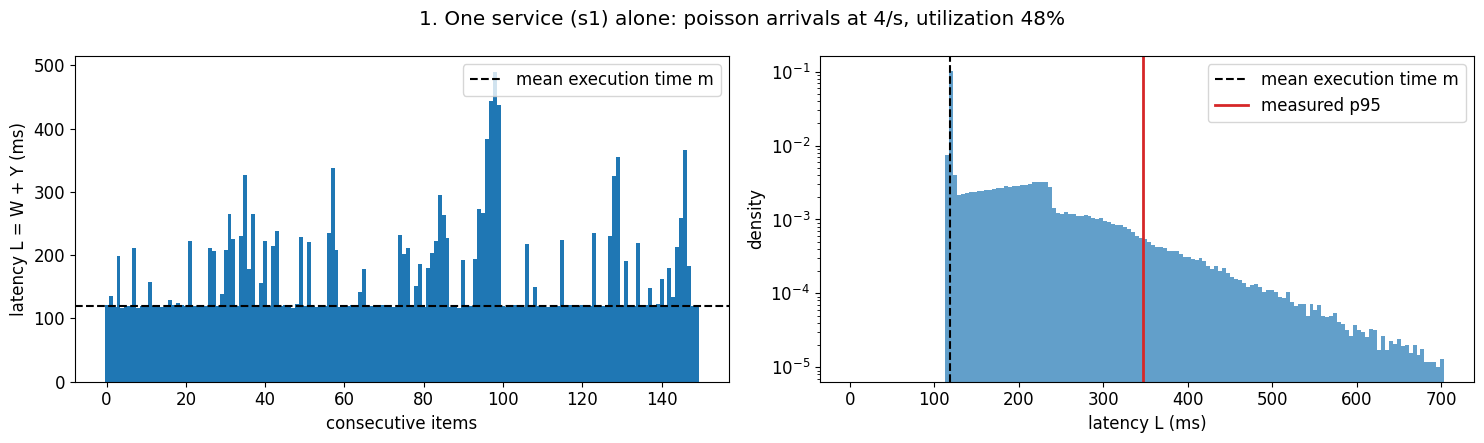

**What this shows** (s1 alone, poisson arrivals at 4 items/s).
- About 47% of the items wait; the others have a latency equal to their execution time, close to 119 ms.
- The items that wait come in runs (left), and their latencies form a long tail that falls along a straight line on the logarithmic axis (right): an exponential tail. Section 2 computes its rate without any simulation. The measured p95 is 347 ms, which is 2.9× the mean execution time, although the service is busy only 48% of the time. A bound that ignores the queue is far too low.

In [2]:
m1, sigma1 = means3[0], sds3[0]
single_latency = simulate(means3[:1], sds3[:1], np.random.default_rng([seed, 1]), **arrivals)[0][:, 0]   # latency (s) of every item at s1 alone
single_measured = np.quantile(single_latency, 1 - epsilons)                                             # measured quantile for every epsilon
n_shown = 150                                                                                           # consecutive items in the left panel

fig, (ax_items, ax_hist) = plt.subplots(1, 2, figsize=(15, 4.5))
ax_items.bar(np.arange(n_shown), single_latency[:n_shown] * 1e3, width=1.0, color="tab:blue")
ax_items.axhline(m1 * 1e3, color="black", linestyle="--", label="mean execution time m")
ax_items.set_xlabel("consecutive items")
ax_items.set_ylabel("latency L = W + Y (ms)")
ax_items.legend(loc="upper right")
ax_hist.hist(single_latency * 1e3, bins=150, range=(0, np.quantile(single_latency, 0.999) * 1e3), density=True, color="tab:blue", alpha=0.7)
ax_hist.set_yscale("log")
ax_hist.axvline(m1 * 1e3, color="black", linestyle="--", label="mean execution time m")
ax_hist.axvline(np.quantile(single_latency, 1 - epsilon) * 1e3, color="tab:red", linewidth=2, label=f"measured {p_label}")
ax_hist.set_xlabel("latency L (ms)")
ax_hist.set_ylabel("density")
ax_hist.legend(loc="upper right")
fig.suptitle(f"1. One service (s1) alone: {arrivals['process']} arrivals at {arrival_rate:g}/s, utilization {arrival_rate * m1:.0%}")
plt.tight_layout()
plt.show()

waiting_share = np.mean(single_latency > m1 + 3 * sigma1)   # items whose latency is clearly above any execution time
display(Markdown(
    f"**What this shows** (s1 alone, {arrivals['process']} arrivals at {arrival_rate:g} items/s).\n"
    f"- About {waiting_share:.0%} of the items wait; the others have a latency equal to their execution time, close to {ms(m1)}.\n"
    f"- The items that wait come in runs (left), and their latencies form a long tail that falls along a straight line on the logarithmic axis "
    f"(right): an exponential tail. Section 2 computes its rate without any simulation. The measured {p_label} is "
    f"{ms(np.quantile(single_latency, 1 - epsilon))}, which is {np.quantile(single_latency, 1 - epsilon) / m1:.1f}× the mean execution time, "
    f"although the service is busy only {arrival_rate * m1:.0%} of the time. A bound that ignores the queue is far too low."
))

## 2. The Shared Tool: Moment Generating Functions

Both versions of Pegasus use the same tool to bound the running sum of Section 1. It has three ingredients
(`explain_1_why_chernoff_mgf.ipynb` treats them in more depth).

**Ingredient 1: an exponential turns a tail into an average (Chernoff).** For any random quantity $Z$ and any number
$\theta > 0$ (unit 1/s), the event $Z \ge d$ is the same as $e^{\theta Z} \ge e^{\theta d}$. A positive quantity can
exceed a level only as often as its average allows (Markov's inequality), so

$$P(Z \ge d) \;\le\; \mathbb{E}\bigl[e^{\theta Z}\bigr]\; e^{-\theta d}.$$

The average $\mathbb{E}[e^{\theta Z}]$ is called the *moment generating function* (MGF) of $Z$ at $\theta$. The bound
holds for every $\theta$, so one may pick the $\theta$ that gives the smallest $d$.

**Ingredient 2: the MGF of a sum of independent quantities is the product of their MGFs.** This is why the exponential
is used: sums, which is what a queue is made of, turn into products.

**Ingredient 3: the two MGFs of a service are known in closed form.**
- Execution time, Gaussian with mean $m$ and standard deviation $\sigma$:
  $M_Y(\theta) = \mathbb{E}[e^{\theta Y}] = \exp(\theta m + \theta^2\sigma^2/2)$. It is above 1 and grows with $\theta$.
- Gap between Poisson arrivals at rate $\lambda$: $\mathbb{E}[e^{-\theta T}] = \lambda / (\lambda + \theta)$. The minus
  sign is there because a gap *reduces* the running sum. It is below 1 and falls with $\theta$.

**One step of the running sum.** A step adds $Y - T$. Its MGF is the product of the two (ingredient 2):

$$\varphi(\theta) \;=\; M_Y(\theta)\cdot \mathbb{E}\bigl[e^{-\theta T}\bigr].$$

(Queueing theory reserves $\rho$ for the utilization, so this factor gets its own symbol; it is not the density of the
normal distribution, which does not occur in this notebook.) $\varphi(\theta)$ is the factor by which one more waiting
item multiplies the average of $e^{\theta \cdot \text{sum}}$.
While $\varphi(\theta) < 1$, longer runs are exponentially less likely, which is what a bound needs. $\varphi(0) = 1$; for
small $\theta$ it falls below 1 exactly when $m < 1/\lambda$, i.e. when the utilization $\rho$ is below 1 and the service is fast enough on average; for
large $\theta$ the execution time wins and $\varphi$ rises above 1 again. The value where it crosses 1 again is called
$\theta^*$.

**$\theta^*$ is the one number that matters per service.** It is the rate at which the tail of the waiting time falls:
$P(W > w)$ shrinks like $e^{-\theta^* w}$. A large $\theta^*$ means long waits are very rare; a slow or heavily loaded
service has a small $\theta^*$.

The figure below shows $\varphi(\theta)$ (vertical axis) over $\theta$ (horizontal axis, in 1/s, logarithmic) for the
three services, with a dot at each $\theta^*$. Look at where each curve crosses the horizontal line at 1.

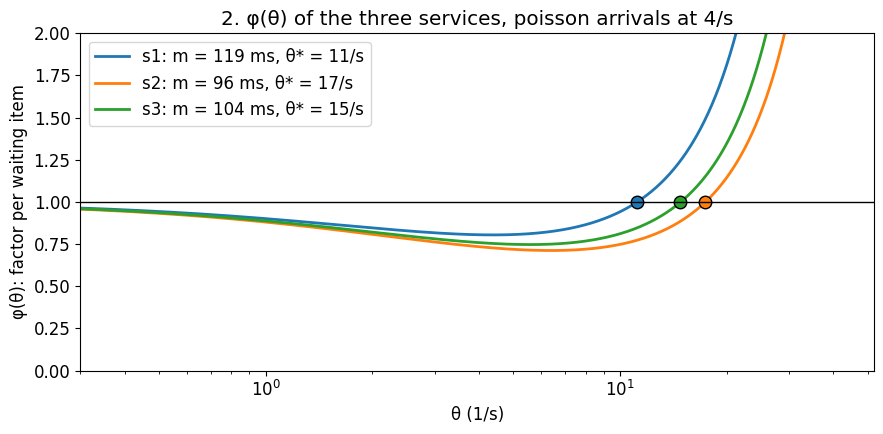

**What this shows** (poisson arrivals at 4 items/s).
- Every curve starts at 1, dips below it and crosses it again at its θ*. Left of θ* the service can be bounded; right of it not.
- The slowest service, s1 (119 ms), has the smallest θ* = 11/s: every further 90 ms of waiting (1/θ*) is only e ≈ 2.7 times less likely. The fastest service, s2 (96 ms), has θ* = 17/s, i.e. the same factor already every 58 ms.
- The slowest service has the heaviest waiting-time tail. Section 4 shows that this matters differently for the two versions.

In [3]:
log_gap = log_interarrival_mgf(theta=THETA_GRID, **arrivals)                                         # ln E[exp(-theta T)] on the grid of theta
theta_stars = np.array([martingale_theta(np.array([mean]), np.array([sd ** 2]), **arrivals)[0] for mean, sd in zip(means3, sds3)])

shown = THETA_GRID < 3 * theta_stars.max()                                                           # beyond that range phi(theta) only grows
theta_axis, log_gap = THETA_GRID[shown], log_gap[shown]

fig, ax = plt.subplots(figsize=(9, 4.5))
for k, (mean, sd, theta_star, color) in enumerate(zip(means3, sds3, theta_stars, ["tab:blue", "tab:orange", "tab:green"]), start=1):
    ax.semilogx(theta_axis, np.exp(theta_axis * mean + 0.5 * theta_axis ** 2 * sd ** 2 + log_gap), color=color, linewidth=2,
                label=f"s{k}: m = {ms(mean)}, θ* = {theta_star:.0f}/s")
    ax.plot(theta_star, 1.0, "o", color=color, markersize=9, markeredgecolor="black")
ax.axhline(1.0, color="black", linewidth=1)
ax.set_xlim(0.3, 3 * theta_stars.max())
ax.set_ylim(0, 2)
ax.set_xlabel("θ (1/s)")
ax.set_ylabel("φ(θ): factor per waiting item")
ax.legend(loc="upper left")
ax.set_title(f"2. φ(θ) of the three services, {arrivals['process']} arrivals at {arrival_rate:g}/s")
plt.tight_layout()
plt.show()

slowest, fastest = int(np.argmax(means3)), int(np.argmin(means3))
display(Markdown(
    f"**What this shows** ({arrivals['process']} arrivals at {arrival_rate:g} items/s).\n"
    f"- Every curve starts at 1, dips below it and crosses it again at its θ*. Left of θ* the service can be bounded; right of it not.\n"
    f"- The slowest service, s{slowest + 1} ({ms(means3[slowest])}), has the smallest θ* = {theta_stars[slowest]:.0f}/s: every further "
    f"{ms(1 / theta_stars[slowest])} of waiting (1/θ*) is only e ≈ 2.7 times less likely. The fastest service, s{fastest + 1} "
    f"({ms(means3[fastest])}), has θ* = {theta_stars[fastest]:.0f}/s, i.e. the same factor already every {ms(1 / theta_stars[fastest])}.\n"
    f"- The slowest service has the heaviest waiting-time tail. Section 4 shows that this matters differently for the two versions."
))

## 3. Bounding One Service

Before any chain: how does the tool of Section 2 give a latency bound for *one* service? There are two ways, and each
version of Pegasus is built on one of them.

- **3a. Union bound over queue lengths, with Chernoff:** bound every length of the running sum separately and add up.
  This is the step that Pegasus SNC generalizes to a chain.
- **3b. Martingale bound:** bound the largest value of the running sum in one step. This is the node bound of
  Pegasus per node.
- **3c. Results:** both against the simulated service.

The cell below creates the container for the two curves; both are computed for s1 alone (simulated in Section 1), for
every violation probability in `epsilons`, and compared in 3c.

In [4]:
node_curves = {}                                         # name -> latency bound (s) of s1 alone for every violation probability in `epsilons`
mean1, var1 = np.array([m1]), np.array([sigma1 ** 2])   # mean (s) and variance (s^2) of the execution time of s1, in the input format of the bounds

### 3a. Union Bound over Queue Lengths, with Chernoff

From Section 1, the latency is the item's own execution time plus the largest running sum:
$L = \max_{n \ge 0} Z_n$ with $Z_n = Y_0 + \sum_{i=1}^{n}(Y_i - T_i)$, where $n$ is the number of items in the busy
run before it ($n = 0$: the item does not wait).

1. **Union bound over $n$.** The maximum exceeds $d$ only if at least one $Z_n$ does, so
   $P(L > d) \le \sum_{n \ge 0} P(Z_n > d)$.
2. **Chernoff for every $n$** (ingredients 1 and 2 of Section 2): $Z_n$ consists of $n + 1$ execution times and $n$
   gaps, so $P(Z_n > d) \le e^{-\theta d}\, M_Y(\theta)\, \varphi(\theta)^n$.
3. **Add up.** For $\varphi(\theta) < 1$ the terms form a geometric series:

$$P(L > d) \;\le\; e^{-\theta d}\,\frac{M_Y(\theta)}{1 - \varphi(\theta)}.$$

Setting the right side to $\varepsilon$ and solving for $d$ gives a bound with three terms, minimized over $\theta$:

$$d(\varepsilon) = \min_{\theta:\ \varphi(\theta) < 1}\;\Bigl[\;
\underbrace{\frac{\ln M_Y(\theta)}{\theta}}_{\text{execution time}} \;+\;
\underbrace{\frac{-\ln(1 - \varphi(\theta))}{\theta}}_{\text{queueing term}} \;+\;
\underbrace{\frac{\ln(1/\varepsilon)}{\theta}}_{\text{price of confidence}}\;\Bigr].$$

- The *execution time* term is $m + \theta\sigma^2/2$ for a Gaussian: slightly above the mean.
- The *queueing term* is the cost of step 1: every possible queue length was counted separately. It grows without
  limit as $\theta$ approaches $\theta^*$, where $\varphi = 1$.
- The *price of confidence* falls with $\theta$: a smaller $\varepsilon$ costs $\ln(1/\varepsilon)/\theta$ more.

The last two terms pull in opposite directions: the price of confidence wants $\theta$ as large as possible, the
queueing term keeps it away from $\theta^*$.

**Assumptions:** the execution times of different items are independent, the gaps are independent, and both MGFs are
correct. **Guarantee:** yes, under these assumptions.

In [5]:
node_curves["3a union over queue lengths + Chernoff"] = np.array([snc_latency_bound(mean1, var1, epsilon=e, **arrivals)[0] for e in epsilons])

### 3b. Martingale Bound

Step 1 of 3a is wasteful: the events "the running sum is high after $n$ items" overlap heavily for neighboring $n$, yet
each was counted in full. The martingale bound treats the whole running sum $R_n = \sum_{i=1}^{n}(Y_i - T_i)$ at once.

1. **A fair game.** Look at $e^{\theta^* R_n}$. Every further item multiplies it by $e^{\theta^*(Y - T)}$, a factor with
   average $\varphi(\theta^*) = 1$ (Section 2). So $e^{\theta^* R_n}$ starts at 1 and neither grows nor shrinks on
   average: it behaves like the fortune of a player in a fair game (a *martingale*).
2. **A fair game rarely reaches a large fortune.** A player who starts with 1 reaches a fortune of $F$ at *any* time
   with probability at most $1/F$ (Ville's maximal inequality). The waiting time exceeds $w$ when the running sum does,
   i.e. when the fortune reaches $F = e^{\theta^* w}$:

$$P(W > w) \;\le\; e^{-\theta^* w}.$$

   There is no sum over $n$ and therefore no queueing term, and the bound uses $\theta^*$ itself, the largest rate
   there is. This is Kingman's bound.
3. **Add the item's own execution time.** $L = W + Y$, and the execution time $Y$ of the item is independent of how
   long it waited. Averaging the bound of step 2 over a Gaussian $Y$ gives a closed formula:

$$P(L > d) \;\le\; P(Y > d) \;+\; \exp\!\bigl(-\theta^*(d - m) + \tfrac{1}{2}{\theta^*}^2\sigma^2\bigr)\;
\Phi\!\Bigl(\frac{d - m - \theta^*\sigma^2}{\sigma}\Bigr),$$

   with $\Phi$ the standard normal distribution function. The first term is the case in which the execution time alone
   exceeds $d$; the second is waiting plus execution. $d(\varepsilon)$ is the value at which the right side equals
   $\varepsilon$ (found by bisection).

**Assumptions:** those of 3a. **Guarantee:** yes, under these assumptions.

In [6]:
node_curves["3b martingale"] = np.array([martingale_closed_form_node_bound(mean1, var1, epsilon=e, **arrivals)[0] for e in epsilons])

### 3c. Results: One Service

The figure below shows the latency (ms, vertical axis) that is exceeded with probability $\varepsilon$ (horizontal
axis, logarithmic, stricter to the right): the measured quantile of the simulation of Section 1 and the two bounds. A
bound must lie above the black line; the closer, the tighter. This is one service at one configuration: it shows how
the two bounds behave, not their coverage, which the evaluation checks over many configurations (`2a_base_case.ipynb` to `2e_iterative.ipynb`,
B.1).

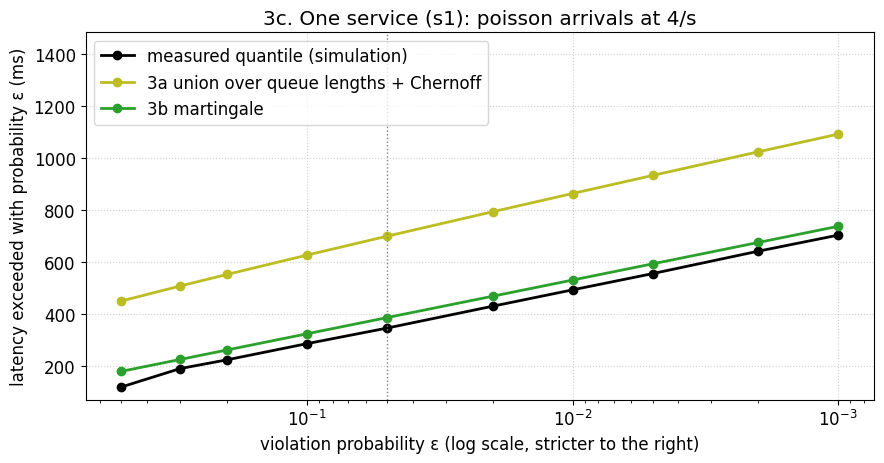

**What this shows** (s1 alone, poisson arrivals at 4 items/s, one configuration).
- **3a union over queue lengths + Chernoff:** 2.02× the measured quantile at ε = 0.05, between 1.55× and 3.72× over all ε shown. It stays above the measured quantile everywhere.
- **3b martingale:** 1.12× the measured quantile at ε = 0.05, between 1.05× and 1.49× over all ε shown. It stays above the measured quantile everywhere.
- All three lines have the same slope at small ε: the tail falls at the rate θ* of Section 2, which both bounds know. They differ in their level: the gap between the two bounds is the queueing term of 3a, which the martingale bound does not pay.

In [7]:
at_eps = int(np.argmin(np.abs(epsilons - epsilon)))   # index of the violation probability `epsilon` in `epsilons`
node_colors = {"3a union over queue lengths + Chernoff": "tab:olive", "3b martingale": "tab:green"}

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.semilogx(epsilons, single_measured * 1e3, "o-", color="black", linewidth=2, label="measured quantile (simulation)")
for name, curve in node_curves.items():
    ax.semilogx(epsilons, curve * 1e3, "o-", color=node_colors[name], linewidth=2, label=name)
ax.axvline(epsilon, color="gray", linestyle=":", linewidth=1)
ax.invert_xaxis()
ax.set_xlabel("violation probability ε (log scale, stricter to the right)")
ax.set_ylabel("latency exceeded with probability ε (ms)")
ax.set_ylim(top=1.3 * ax.get_ylim()[1])   # room for the legend above the curves
ax.legend(loc="upper left")
ax.grid(True, linestyle=":", alpha=0.6)
ax.set_title(f"3c. One service (s1): {arrivals['process']} arrivals at {arrival_rate:g}/s")
plt.tight_layout()
plt.show()

node_ratio = {name: curve / single_measured for name, curve in node_curves.items()}
display(Markdown(
    f"**What this shows** (s1 alone, {arrivals['process']} arrivals at {arrival_rate:g} items/s, one configuration).\n"
    + "".join(f"- **{name}:** {ratio[at_eps]:.2f}× the measured quantile at ε = {epsilon:g}, between {ratio.min():.2f}× and {ratio.max():.2f}× "
              f"over all ε shown. {'It stays above the measured quantile everywhere.' if ratio.min() >= 1 else 'It falls below the measured quantile somewhere.'}\n"
              for name, ratio in node_ratio.items())
    + f"- All three lines have the same slope at small ε: the tail falls at the rate θ* of Section 2, which both bounds know. They differ in "
    f"their level: the gap between the two bounds is the queueing term of 3a, which the martingale bound does not pay."
))

## 4. Bounding a Chain

Now the chain $s_1 \to s_2 \to s_3$: an item leaves $s_1$ and immediately enters the queue of $s_2$, and so on. The
end-to-end latency is the sum of its latencies at the $K = 3$ services, $L = L_1 + L_2 + L_3$ (the paper writes the
chain as $S$ and its depth as $|S|$). The two versions of
Pegasus are two ways to bound this sum:

- **4a. Union bound over martingale node bounds** (Pegasus per node): one bound per service from 3b, added.
- **4b. Network service curve** (Pegasus SNC): the path argument of 3a, applied to the whole chain at once.
- **4c. Results:** both against the simulated chain, with the parts each bound consists of.

The cell below simulates the chain and creates the container for the two curves over $\varepsilon$.

In [8]:
chain_per_service, chain_latency = simulate(means3, sds3, np.random.default_rng([seed, 2]), **arrivals)   # latency (s) per service and end to end
chain_measured = np.quantile(chain_latency, 1 - epsilons)                                                   # measured end-to-end quantile per epsilon
chain_curves = {}                                                                                           # name -> end-to-end bound (s) per epsilon


def per_node_bound(means, sds, eps, **arrival_process):
    # 4a: union bound over the martingale node bounds, each service at eps / K
    nodes = martingale_closed_form_node_bounds(beliefs_of(means, sds), epsilon=eps / len(means), **arrival_process)
    return float(nodes.sum())


def snc_bound(means, sds, eps, **arrival_process):
    # 4b: network service curve for independent services (no Hoelder step), the whole chain at eps
    return float(network_service_bound(beliefs_of(means, sds), epsilon=eps, holder_exponents=[1] * len(means), **arrival_process)[0])


def snc_terms(means, sds, eps, **arrival_process):
    # 4b: the three terms of snc_bound (execution time, queueing term, price of confidence), in s
    return [float(term[0]) for term in network_bound_terms(beliefs_of(means, sds), epsilon=eps, **arrival_process)[:3]]

### 4a. Union Bound over Martingale Node Bounds (Pegasus per Node)

**The rule.** Give every service $k$ its own bound $d_k$ that it exceeds with probability at most $\varepsilon / K$, and
add them: $d = d_1 + \dots + d_K$.

**Why it is a guarantee.** If the end-to-end latency exceeds $d_1 + \dots + d_K$, then at least one service exceeded its
own $d_k$; otherwise the sum would be at most $d$. The probability that at least one of $K$ events happens is at most the
sum of their probabilities (union bound), $K \cdot \varepsilon / K = \varepsilon$. Nothing in this argument asks how
the services depend on each other: **it holds for any dependence between the services.**

**What it costs.** Each service is bounded at the stricter level $\varepsilon / K$ instead of $\varepsilon$. With the
node bound of 3b, the waiting time behind level $\varepsilon/K$ is about $\ln(K/\varepsilon)/\theta^*_k$, so the chain
pays roughly

$$\sum_{k=1}^{K} \frac{\ln(K/\varepsilon)}{\theta^*_k}\,,$$

i.e. **the price of confidence once per service**, each at that service's own rate $\theta^*_k$. The sum $d$ is exceeded
only if all services are late at once or one is extremely late; assuming that every service uses its full allowance at
the same time is what makes the bound loose for long chains.

**Every service sees the external arrivals.** A later service receives the departures of the service before it, not
the external (Poisson) arrivals; the node bound of 3b is applied to it all the same (the paper's assumption on
internal arrivals). A service with one worker releases its items at least one execution time apart, which could
tighten the bound of the service after it; Pegasus does not use this minimum spacing.

**Assumptions:** those of 3b per service. **Guarantee:** yes, for any dependence between the services.

In [9]:
chain_curves["4a union bound, martingale nodes (Pegasus per node)"] = np.array([per_node_bound(means3, sds3, e, **arrivals) for e in epsilons])

### 4b. Network Service Curve (Pegasus SNC)

**The idea.** Do not bound the services one by one. Write down the end-to-end latency of the chain exactly, and apply
the three steps of 3a to it.

**The end-to-end latency as a maximum over paths**, for two services. Item $n$ leaves $s_1$ at the time
$\max_{j \le n}\,[A_j + Y_1(j) + \dots + Y_1(n)]$, where $A_j$ is the arrival time of item $j$ and $Y_1(i)$ the
execution time of item $i$ at $s_1$: some earlier item $j$ found $s_1$ idle, and since then $s_1$ worked without
pause on the items $j$ to $n$. The same holds at $s_2$, whose arrivals are the departures of $s_1$. Putting one into
the other and subtracting the arrival time of item $n$ gives its end-to-end latency:

$$L(n) = \max_{j \le m \le n}\;\Bigl[\;\sum_{i=j}^{m} Y_1(i) \;+\; \sum_{i=m}^{n} Y_2(i) \;-\; (A_n - A_j)\Bigr].$$

Each pair $(j, m)$ is a *path*: $s_1$ works on the items $j$ to $m$, then $s_2$ works on the items $m$ to $n$, and
$A_n - A_j$ is the sum of the $n - j$ gaps in between. The latency is set by the worst path. For $K$ services a path
has $K$ such stretches. Only the external arrivals appear: what the later services receive is already contained in
the formula, so no assumption about their arrivals is needed.

**The three steps of 3a.**
1. Union bound over all paths.
2. Chernoff for every path. A path with $a$ extra items at $s_1$ and $b$ extra items at $s_2$ consists of $a + 1$
   execution times of $s_1$, $b + 1$ of $s_2$, and $a + b$ gaps. **If the execution times at $s_1$ and $s_2$ are
   independent**, the MGF of the path is the product (ingredient 2):
   $M_1(\theta)\,M_2(\theta)\,\varphi_1(\theta)^a\,\varphi_2(\theta)^b$, with $M_k$ and $\varphi_k$ the functions of Section 2
   for service $k$.
3. Add up over $a$ and $b$: two geometric series.

For $K$ services:

$$P(L > d) \;\le\; e^{-\theta d}\,\prod_{k=1}^{K} \frac{M_k(\theta)}{1 - \varphi_k(\theta)}
\qquad\Longrightarrow\qquad
d(\varepsilon) = \min_{\theta}\;\Bigl[\;
\underbrace{\sum_k \frac{\ln M_k(\theta)}{\theta}}_{\text{execution times}} \;+\;
\underbrace{\sum_k \frac{-\ln(1 - \varphi_k(\theta))}{\theta}}_{\text{queueing terms}} \;+\;
\underbrace{\frac{\ln(1/\varepsilon)}{\theta}}_{\text{price of confidence}}\;\Bigr],$$

minimized over the $\theta$ with $\varphi_k(\theta) < 1$ for *every* service. It is the formula of 3a with one execution
term and one queueing term per service, but **the price of confidence only once**, however long the chain is.

**What it costs.**
- *One $\theta$ for all services.* It must stay below the smallest $\theta^*_k$, the one of the slowest service. A
  single slow service sets the rate at which the whole chain pays for confidence.
- *One queueing term per service,* the wasteful step of 3a, now paid $K$ times.
- *Independence.* Step 2 multiplies MGFs of different services. If an item that is slow at one service tends to be
  slow at the next, the product is wrong and the bound is no longer a guarantee. It can be repaired with Hölder's
  inequality, which replaces every variance $\sigma_k^2$ by $p_k\sigma_k^2$ with $\sum_k 1/p_k = 1$ (for equal shares,
  $p_k = K$): valid for any dependence, at the price of a larger variance. Section 5b measures that price.

**Assumptions:** those of 3a, and independent execution times between the services. **Guarantee:** yes, under these
assumptions.

In [10]:
chain_curves["4b network service curve (Pegasus SNC)"] = np.array([snc_bound(means3, sds3, e, **arrivals) for e in epsilons])

### 4c. Results: A Chain of Three Services

*Left:* as in 3c, the end-to-end latency (ms) that is exceeded with probability $\varepsilon$ (horizontal axis,
logarithmic, stricter to the right): measured, and the two bounds.

*Right:* what each bound consists of at $\varepsilon$ = `epsilon`, as a share of the measured quantile (1× = measured,
the horizontal line). The left bar is the per-node bound: the mean execution times of the services, and on top the
allowance for waiting that the node bounds add at level $\varepsilon/K$. The right bar is the SNC bound with its three
terms of 4b. This kind of figure returns in Section 5; read the height of a bar as the tightness of the bound and
the colors as the reason for it.

One chain at one configuration: this shows how the bounds are built, not their coverage (see `2a_base_case.ipynb`, B.1).

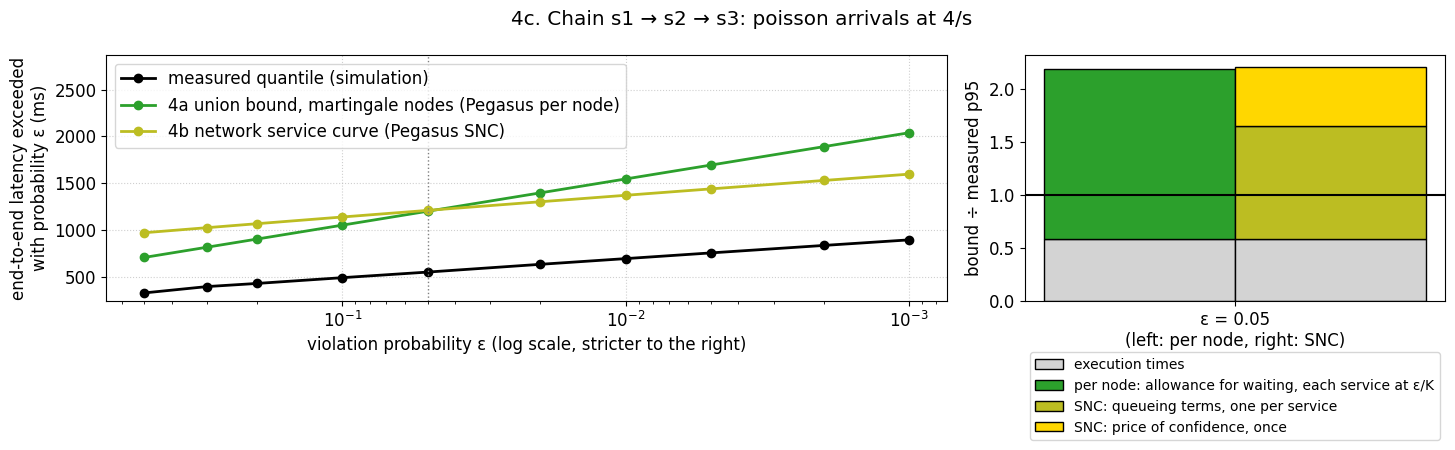

**What this shows** (chain of 3 services, poisson arrivals at 4 items/s, one configuration).
- **4a union bound, martingale nodes (Pegasus per node):** 2.19× the measured quantile at ε = 0.05; 2.17× at ε = 0.5 and 2.28× at ε = 0.001. It stays above the measured quantile everywhere.
- **4b network service curve (Pegasus SNC):** 2.21× the measured quantile at ε = 0.05; 2.98× at ε = 0.5 and 1.79× at ε = 0.001. It stays above the measured quantile everywhere.
- **Over ε.** From the loosest level shown (ε = 0.5) to the strictest (ε = 0.001), the distance between the two bounds shrinks from 264 ms to -443 ms: the SNC line is flatter. The SNC bound pays ln(1/ε) once and the per-node bound once per service, so every stricter ε costs SNC less; the SNC bound in turn carries its queueing terms at every ε, also where little confidence is asked for.
- **Parts at ε = 0.05.** Of the SNC bound, 48% are queueing terms and 25% the price of confidence. Of the per-node bound, 73% are the allowance for waiting.

In [11]:
chain_colors = {"4a union bound, martingale nodes (Pegasus per node)": "tab:green", "4b network service curve (Pegasus SNC)": "tab:olive"}
PER_NODE, SNC = chain_colors


def parts_figure(ax, labels, mean_sums, per_node, snc_parts, measured):
    # Two bars per setting, as shares of the measured quantile. Left: per-node bound = mean execution times + allowance for waiting.
    # Right: SNC bound = execution times + queueing terms + price of confidence. snc_parts: three sequences, one value per setting.
    x, width = np.arange(len(labels)), 0.38
    mean_sums, per_node, measured = (np.asarray(values, dtype=float) for values in (mean_sums, per_node, measured))
    execution, queueing, confidence = (np.asarray(part, dtype=float) / measured for part in snc_parts)
    ax.bar(x - width / 2, mean_sums / measured, width, color="lightgray", edgecolor="black", label="execution times")
    ax.bar(x - width / 2, (per_node - mean_sums) / measured, width, bottom=mean_sums / measured, color="tab:green", edgecolor="black",
           label="per node: allowance for waiting, each service at ε/K")
    ax.bar(x + width / 2, execution, width, color="lightgray", edgecolor="black")
    ax.bar(x + width / 2, queueing, width, bottom=execution, color="tab:olive", edgecolor="black", label="SNC: queueing terms, one per service")
    ax.bar(x + width / 2, confidence, width, bottom=execution + queueing, color="gold", edgecolor="black", label="SNC: price of confidence, once")
    ax.axhline(1.0, color="black", linewidth=1.5)
    ax.set_xticks(x, labels)
    ax.set_ylabel(f"bound ÷ measured {p_label}")


fig, (ax_curve, ax_parts) = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw=dict(width_ratios=[2, 1]))
ax_curve.semilogx(epsilons, chain_measured * 1e3, "o-", color="black", linewidth=2, label="measured quantile (simulation)")
for name, curve in chain_curves.items():
    ax_curve.semilogx(epsilons, curve * 1e3, "o-", color=chain_colors[name], linewidth=2, label=name)
ax_curve.axvline(epsilon, color="gray", linestyle=":", linewidth=1)
ax_curve.invert_xaxis()
ax_curve.set_xlabel("violation probability ε (log scale, stricter to the right)")
ax_curve.set_ylabel("end-to-end latency exceeded\nwith probability ε (ms)")
ax_curve.set_ylim(top=1.35 * ax_curve.get_ylim()[1])   # room for the legend above the curves
ax_curve.legend(loc="upper left")
ax_curve.grid(True, linestyle=":", alpha=0.6)
chain_terms = snc_terms(means3, sds3, epsilon, **arrivals)
parts_figure(ax_parts, [f"ε = {epsilon:g}\n(left: per node, right: SNC)"], [means3.sum()], [chain_curves[PER_NODE][at_eps]],
             [[term] for term in chain_terms], [chain_measured[at_eps]])
ax_parts.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), fontsize=10)
fig.suptitle(f"4c. Chain s1 → s2 → s3: {arrivals['process']} arrivals at {arrival_rate:g}/s")
plt.tight_layout()
plt.show()

chain_ratio = {name: curve / chain_measured for name, curve in chain_curves.items()}
display(Markdown(
    f"**What this shows** (chain of {K3} services, {arrivals['process']} arrivals at {arrival_rate:g} items/s, one configuration).\n"
    + "".join(f"- **{name}:** {ratio[at_eps]:.2f}× the measured quantile at ε = {epsilon:g}; {ratio[0]:.2f}× at ε = {epsilons[0]:g} and "
              f"{ratio[-1]:.2f}× at ε = {epsilons[-1]:g}. "
              f"{'It stays above the measured quantile everywhere.' if ratio.min() >= 1 else 'It falls below the measured quantile somewhere.'}\n"
              for name, ratio in chain_ratio.items())
    + f"- **Over ε.** From the loosest level shown (ε = {epsilons[0]:g}) to the strictest (ε = {epsilons[-1]:g}), the distance between the two "
    f"bounds shrinks from {(chain_curves[SNC][0] - chain_curves[PER_NODE][0]) * 1e3:.0f} ms to "
    f"{(chain_curves[SNC][-1] - chain_curves[PER_NODE][-1]) * 1e3:.0f} ms: the SNC line is flatter. The SNC bound pays ln(1/ε) once and the "
    f"per-node bound once per service, so every stricter ε costs SNC less; the SNC bound in turn carries its queueing terms at every ε, also "
    f"where little confidence is asked for.\n"
    f"- **Parts at ε = {epsilon:g}.** Of the SNC bound, {chain_terms[1] / sum(chain_terms):.0%} are queueing terms and "
    f"{chain_terms[2] / sum(chain_terms):.0%} the price of confidence. Of the per-node bound, "
    f"{1 - means3.sum() / chain_curves[PER_NODE][at_eps]:.0%} are the allowance for waiting."
))

## 5. Strengths and Weaknesses, Tested

Section 4 gave the reasons why each version should be strong or weak. This section tests three of them, each by
changing one thing about the chain. The two bounds are those of 4a and 4b; every experiment simulates the chain anew
and compares the bounds at $\varepsilon$ = `epsilon`.

- **5a. Depth of the chain:** the per-node bound pays for confidence once per service, the SNC bound once in total.
- **5b. Dependent services:** the per-node bound holds for any dependence, the SNC bound assumes independence.
- **5c. Bursty arrivals:** the SNC bound pays a queueing term per service as if every service saw the external
  arrivals.

The fourth property, the violation probability, is already in 4c (left panel). Two properties are the same for both
versions and are tested in the evaluation instead: both need a correct mean and variance per service
(`2b_evidence.ipynb`, B.2), and both assume Gaussian execution times (B.5).

Every figure of this section uses the bars of 4c. All experiments use one configuration and one seed; they show
mechanisms, and the evaluation repeats them over configurations and seeds (B.3 for the depth, B.4 for the arrivals).

### 5a. Depth of the Chain

Chains of $K$ different services, $s_1 \to \dots \to s_K$, for every depth $K$ in `depths`. The deepest chain is
simulated once; the chain of depth $K$ is its first $K$ services, whose latencies do not depend on what follows them. The figure shows the two bars
of 4c for every depth $K$ (horizontal axis).

What to expect from Section 4: at $K = 1$ the per-node bound is the martingale bound of 3b and the SNC bound the
looser bound of 3a. With growing $K$ the per-node bound bounds every service at the stricter level $\varepsilon/K$,
while the SNC bound adds one queueing term per service and keeps its single price of confidence.

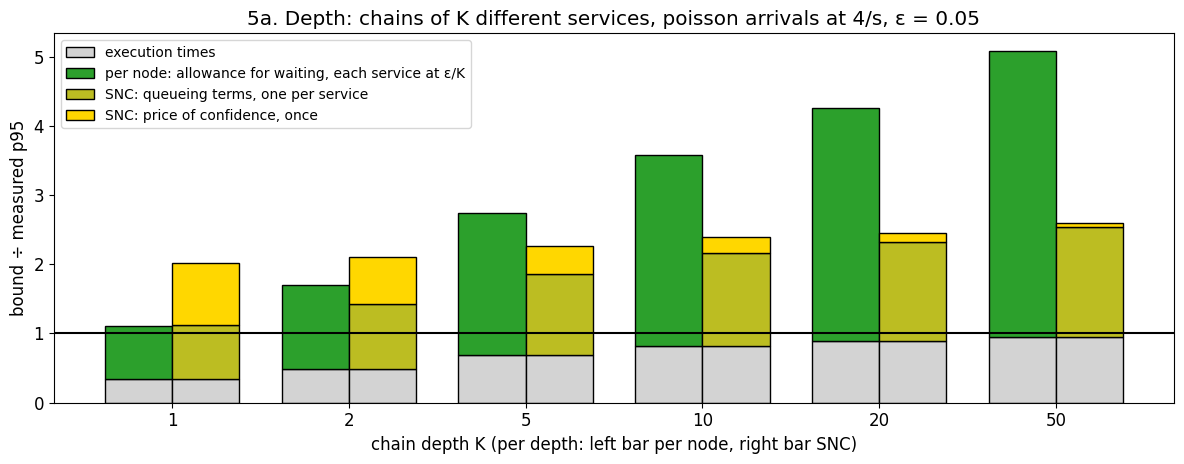

**What this shows** (poisson arrivals at 4 items/s, ε = 0.05, one configuration).
- **Per node:** 1.11× the measured p95 at depth 1 and 5.08× at depth 50. Its allowance for waiting grows faster than the measured latency, because every further service is bounded at a stricter level ε/K and all allowances are added as if every service were late at once.
- **SNC:** 2.01× at depth 1 and 2.60× at depth 50. At depth 1 it is the looser node bound of 3a; with growing depth its single price of confidence is shared by more and more services (44% of the bound at depth 1, 2% at depth 50).
- **Crossover.** The SNC bound is the tighter one from depth 5 on.
- **The slowest service.** Among the 50 services, s32 is the slowest (129 ms, utilization 52%). The SNC bound must use one θ below the θ* of that service for the whole chain; the per-node bound uses every service's own θ*.

In [12]:
depths = [1, 2, 5, 10, 20, 50]
means_deep, sds_deep = chain_parameters(depths[-1])
deep_per_service = simulate(means_deep, sds_deep, np.random.default_rng([seed, 3]), **arrivals)[0]   # latency (s) per item and service, deepest chain
depth_results = dict(mean_sums=[], per_node=[], snc_parts=[], measured=[])
for depth in depths:
    means, sds = means_deep[:depth], sds_deep[:depth]
    depth_results["mean_sums"].append(means.sum())
    depth_results["measured"].append(np.quantile(deep_per_service[:, :depth].sum(axis=1), 1 - epsilon))
    depth_results["per_node"].append(per_node_bound(means, sds, epsilon, **arrivals))
    depth_results["snc_parts"].append(snc_terms(means, sds, epsilon, **arrivals))
depth_snc = np.array(depth_results["snc_parts"])                         # (depths, 3 terms)
depth_tightness = {PER_NODE: np.array(depth_results["per_node"]) / depth_results["measured"], SNC: depth_snc.sum(axis=1) / depth_results["measured"]}

fig, ax = plt.subplots(figsize=(12, 4.8))
parts_figure(ax, [str(depth) for depth in depths], depth_results["mean_sums"], depth_results["per_node"], depth_snc.T, depth_results["measured"])
ax.set_xlabel("chain depth K (per depth: left bar per node, right bar SNC)")
ax.legend(loc="upper left", fontsize=10)
ax.set_title(f"5a. Depth: chains of K different services, {arrivals['process']} arrivals at {arrival_rate:g}/s, ε = {epsilon:g}")
plt.tight_layout()
plt.show()

crossing = next((depth for depth, per_node, snc in zip(depths, depth_tightness[PER_NODE], depth_tightness[SNC]) if snc < per_node), None)
slowest_deep = int(np.argmax(means_deep))
display(Markdown(
    f"**What this shows** ({arrivals['process']} arrivals at {arrival_rate:g} items/s, ε = {epsilon:g}, one configuration).\n"
    f"- **Per node:** {depth_tightness[PER_NODE][0]:.2f}× the measured {p_label} at depth {depths[0]} and {depth_tightness[PER_NODE][-1]:.2f}× at "
    f"depth {depths[-1]}. Its allowance for waiting grows faster than the measured latency, because every further service is bounded at a "
    f"stricter level ε/K and all allowances are added as if every service were late at once.\n"
    f"- **SNC:** {depth_tightness[SNC][0]:.2f}× at depth {depths[0]} and {depth_tightness[SNC][-1]:.2f}× at depth {depths[-1]}. At depth "
    f"{depths[0]} it is the looser node bound of 3a; with growing depth its single price of confidence is shared by more and more services "
    f"({depth_snc[0, 2] / depth_snc[0].sum():.0%} of the bound at depth {depths[0]}, {depth_snc[-1, 2] / depth_snc[-1].sum():.0%} at depth "
    f"{depths[-1]}).\n"
    + (f"- **Crossover.** The SNC bound is the tighter one from depth {crossing} on.\n" if crossing is not None
       else "- **Crossover.** The per-node bound is the tighter one at every depth shown.\n")
    + f"- **The slowest service.** Among the {depths[-1]} services, s{slowest_deep + 1} is the slowest ({ms(means_deep[slowest_deep])}, utilization "
    f"{arrival_rate * means_deep[slowest_deep]:.0%}). The SNC bound must use one θ below the θ* of that service for the whole chain; the per-node "
    f"bound uses every service's own θ*."
))

### 5b. Dependent Services

So far the execution times of an item at different services were independent. Now they are correlated: the simulator
draws the execution-time noise of an item with a correlation between the services (`item_correlation`), so that an
item that is slow at one service tends to be slow at the others. Three bounds are compared with the simulated chain
$s_1 \to s_2 \to s_3$:

- the per-node bound (4a), valid for any dependence;
- the SNC bound for independent services (4b), **not a guarantee** once the correlation is above 0;
- the SNC bound with the Hölder step (4b), valid for any dependence.

None of the three bounds takes the correlation as an input, so each is one number per panel; only the measured latency moves.
*Left panel:* the execution-time noise of the generated services, a few milliseconds. *Right panel:* the same services
with their noise multiplied by `noise_scale`, i.e. services whose execution time varies strongly from item to item
(the standard deviations are in the panel titles). In both panels the horizontal axis is the correlation and the vertical axis the tightness,
bound ÷ measured percentile; a value below the horizontal line at 1× is a bound that is too low.

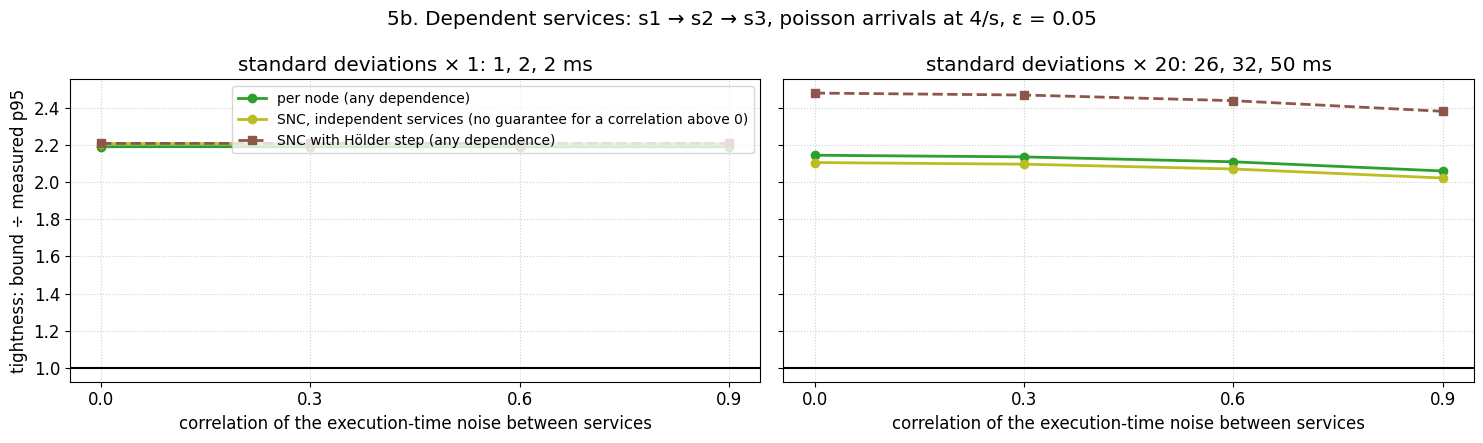

**What this shows** (chain of 3 services, poisson arrivals at 4 items/s, ε = 0.05, one configuration).
- **Noise of the generated services (left):** the measured p95 at a correlation of 0.9 is 1.00× the one at correlation 0; the SNC bound for independent services is at least 2.21× the measured p95 (it stays above it at every correlation); the Hölder step makes the SNC bound 1.00× as large.
- **Noise × 20 (right):** the measured p95 at a correlation of 0.9 is 1.04× the one at correlation 0; the SNC bound for independent services is at least 2.02× the measured p95 (it stays above it at every correlation); the Hölder step makes the SNC bound 1.18× as large.
- **Reading.** Whether dependence matters is decided by how much the execution times vary, not by the correlation alone: the variance is the only place where the Hölder step enters (σ² becomes p·σ²), and it is also what the correlation acts on. That a bound without a guarantee stays above the measured value in one experiment is no proof that it always does; the per-node bound and the Hölder version need no such check.

In [13]:
correlations = [0.0, 0.3, 0.6, 0.9]   # correlation of an item's execution-time noise between the services
noise_scale = 20                      # factor on the standard deviation of every execution time in the right panel
dependence = {}                       # noise factor -> dict of the three bounds (s) and the measured quantile per correlation (s)
for factor in (1, noise_scale):
    sds = sds3 * factor
    holder = float(network_service_bound(beliefs_of(means3, sds), epsilon=epsilon, **arrivals)[0])   # Hoelder exponents tuned by the implementation
    measured = [np.quantile(simulate(means3, sds, np.random.default_rng([seed, 4, factor]), item_correlation=c, **arrivals)[1], 1 - epsilon)
                for c in correlations]
    dependence[factor] = dict(per_node=per_node_bound(means3, sds, epsilon, **arrivals), snc=snc_bound(means3, sds, epsilon, **arrivals),
                              holder=holder, measured=np.array(measured))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
dependence_styles = {"per_node": ("tab:green", "o-", "per node (any dependence)"), "snc": ("tab:olive", "o-", "SNC, independent services (no guarantee for a correlation above 0)"),
                     "holder": ("tab:brown", "s--", "SNC with Hölder step (any dependence)")}
for ax, (factor, result) in zip(axes, dependence.items()):
    for key, (color, style, label) in dependence_styles.items():
        ax.plot(correlations, result[key] / result["measured"], style, color=color, linewidth=2, label=label)
    ax.axhline(1.0, color="black", linewidth=1.5)
    ax.set_xticks(correlations)
    ax.set_xlabel("correlation of the execution-time noise between services")
    ax.set_title(f"standard deviations × {factor}: {', '.join(f'{1e3 * sd:.0f}' for sd in sds3 * factor)} ms")
    ax.grid(True, linestyle=":", alpha=0.6)
axes[0].set_ylabel(f"tightness: bound ÷ measured {p_label}")
axes[0].legend(loc="upper right", fontsize=10)
fig.suptitle(f"5b. Dependent services: s1 → s2 → s3, {arrivals['process']} arrivals at {arrival_rate:g}/s, ε = {epsilon:g}")
plt.tight_layout()
plt.show()


def dependence_text(factor):
    result = dependence[factor]
    lowest = (result["snc"] / result["measured"]).min()
    return (f"the measured {p_label} at a correlation of {correlations[-1]:g} is {result['measured'][-1] / result['measured'][0]:.2f}× the one at correlation 0; the SNC bound "
            f"for independent services is at least {lowest:.2f}× the measured {p_label} "
            f"({'it stays above it at every correlation' if lowest >= 1 else 'it falls below it'}); the Hölder step makes the SNC bound "
            f"{result['holder'] / result['snc']:.2f}× as large")


display(Markdown(
    f"**What this shows** (chain of {K3} services, {arrivals['process']} arrivals at {arrival_rate:g} items/s, ε = {epsilon:g}, one configuration).\n"
    f"- **Noise of the generated services (left):** {dependence_text(1)}.\n"
    f"- **Noise × {noise_scale} (right):** {dependence_text(noise_scale)}.\n"
    f"- **Reading.** Whether dependence matters is decided by how much the execution times vary, not by the correlation alone: the variance is "
    f"the only place where the Hölder step enters (σ² becomes p·σ²), and it is also what the correlation acts on. That a bound without a "
    f"guarantee stays above the measured value in one experiment is no proof that it always does; the per-node bound and the Hölder version "
    f"need no such check."
))

### 5c. Bursty Arrivals

The services are independent again. Now the arrivals change: the gaps are gamma-distributed with the same mean
($1/\lambda$) and a squared coefficient of variation $C^2$ = variance of a gap ÷ (mean of a gap)². $C^2 = 1$ is the
Poisson process used so far; below 1 the arrivals are more regular, above 1 they come in bursts with long pauses.
Both bounds are given the MGF of this gap. The figure shows the two bars of 4c for every $C^2$ (horizontal axis), for
the chain $s_1 \to s_2 \to s_3$.

What to expect from Section 4: a burst mostly queues at the first service, which then releases its items one at a time,
so the later services see more regular arrivals than the first. The SNC bound adds a queueing term for every service
computed from the external gaps; the per-node bound can use the regulated arrivals where the service before is
slower.

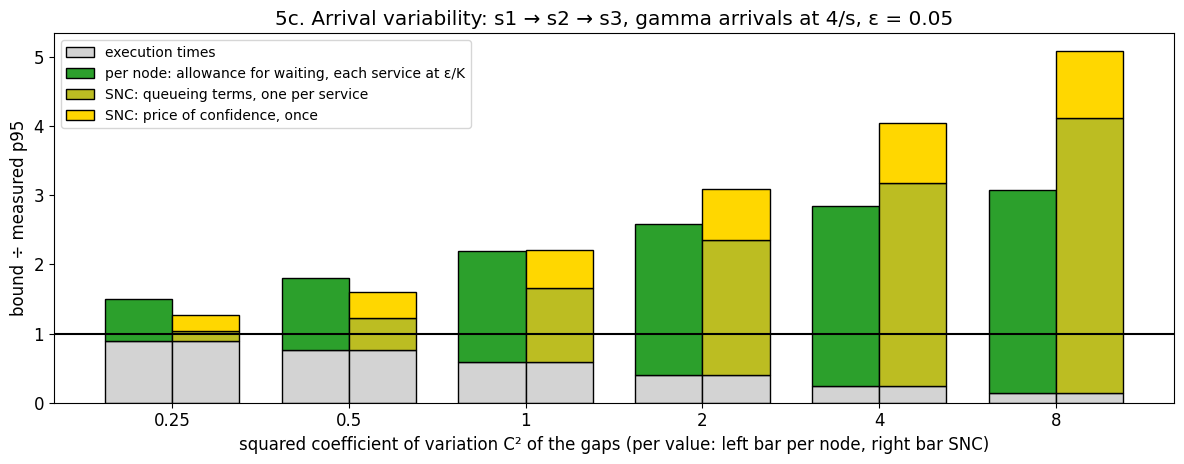

**What this shows** (chain of 3 services, gamma arrivals at 4 items/s, ε = 0.05, one configuration).
- **Measured.** The p95 goes from 361 ms at C² = 0.25 to 2388 ms at C² = 8, at the same arrival rate and utilization.
- **Per node:** 1.50× at C² = 0.25 and 3.07× at C² = 8.
- **SNC:** 1.26× at C² = 0.25 and 5.09× at C² = 8. Its queueing terms are 12% of the bound at C² = 0.25 and 78% at C² = 8.
- **Reading.** The tighter bound is 4b network service curve (Pegasus SNC) for the most regular arrivals and 4a union bound, martingale nodes (Pegasus per node) for the burstiest.

In [14]:
arrival_cv2s = [0.25, 0.5, 1, 2, 4, 8]   # squared coefficient of variation of the gaps between arrivals
burst_results = dict(per_node=[], snc_parts=[], measured=[])
for cv2 in arrival_cv2s:
    gamma_arrivals = dict(process="gamma", rate=arrival_rate, cv2=cv2)
    burst_results["measured"].append(np.quantile(simulate(means3, sds3, np.random.default_rng([seed, 5]), **gamma_arrivals)[1], 1 - epsilon))
    burst_results["per_node"].append(per_node_bound(means3, sds3, epsilon, **gamma_arrivals))
    burst_results["snc_parts"].append(snc_terms(means3, sds3, epsilon, **gamma_arrivals))
burst_snc = np.array(burst_results["snc_parts"])                         # (settings, 3 terms)
burst_tightness = {PER_NODE: np.array(burst_results["per_node"]) / burst_results["measured"], SNC: burst_snc.sum(axis=1) / burst_results["measured"]}

fig, ax = plt.subplots(figsize=(12, 4.8))
parts_figure(ax, [f"{cv2:g}" for cv2 in arrival_cv2s], [means3.sum()] * len(arrival_cv2s), burst_results["per_node"], burst_snc.T, burst_results["measured"])
ax.set_xlabel("squared coefficient of variation C² of the gaps (per value: left bar per node, right bar SNC)")
ax.legend(loc="upper left", fontsize=10)
ax.set_title(f"5c. Arrival variability: s1 → s2 → s3, gamma arrivals at {arrival_rate:g}/s, ε = {epsilon:g}")
plt.tight_layout()
plt.show()

display(Markdown(
    f"**What this shows** (chain of {K3} services, gamma arrivals at {arrival_rate:g} items/s, ε = {epsilon:g}, one configuration).\n"
    f"- **Measured.** The {p_label} goes from {ms(burst_results['measured'][0])} at C² = {arrival_cv2s[0]:g} to {ms(burst_results['measured'][-1])} at "
    f"C² = {arrival_cv2s[-1]:g}, at the same arrival rate and utilization.\n"
    f"- **Per node:** {burst_tightness[PER_NODE][0]:.2f}× at C² = {arrival_cv2s[0]:g} and {burst_tightness[PER_NODE][-1]:.2f}× at C² = {arrival_cv2s[-1]:g}.\n"
    f"- **SNC:** {burst_tightness[SNC][0]:.2f}× at C² = {arrival_cv2s[0]:g} and {burst_tightness[SNC][-1]:.2f}× at C² = {arrival_cv2s[-1]:g}. Its queueing "
    f"terms are {burst_snc[0, 1] / burst_snc[0].sum():.0%} of the bound at C² = {arrival_cv2s[0]:g} and {burst_snc[-1, 1] / burst_snc[-1].sum():.0%} at "
    f"C² = {arrival_cv2s[-1]:g}.\n"
    f"- **Reading.** The tighter bound is {min(burst_tightness, key=lambda name: burst_tightness[name][0])} for the most regular arrivals and "
    f"{min(burst_tightness, key=lambda name: burst_tightness[name][-1])} for the burstiest."
))

## 6. Summary: Which Version for Which Situation

The numbers behind every statement are in the rendered conclusions of the sections named in brackets; they hold for
the chains of this notebook (one configuration, one seed), and the evaluation repeats them over configurations and
seeds.

**What both versions share.** Both need only the mean and the variance of the execution time of every service on its
own, and the MGF of the external gaps. Neither needs a measurement of the composed chain, so both can bound a
composition that was never run. Both are closed formulas with a short numerical search, cheap enough to grade many
candidate compositions. Both are guarantees only relative to their inputs: a wrong mean or a non-Gaussian tail affects
both alike (`2b_evidence.ipynb`, B.2, and `2d_tails_and_percentiles.ipynb`, B.5).

**Pegasus per node (union bound over martingale node bounds)**
- *Strong:* the tightest node bound there is from these inputs, so it is the tighter version for one service and for
  short chains (3c, 5a).
- *Strong:* valid for any dependence between the services, without a check (4a).
- *Strong:* robust against bursty arrivals, where it stays far tighter than SNC (5c); every service is bounded at its
  own rate $\theta^*_k$, so one slow service does not affect the bounds of the others, and a service behind a slower
  one is recognized as practically free of waiting.
- *Strong:* it yields one bound per service. That shows which service uses up the latency budget, and when one service
  of a composition is exchanged, only its own node bound and that of its successor change.
- *Weak:* it pays for confidence once per service and adds the allowances as if every service were late at the same
  time, so it gets looser with every further service (5a).

**Pegasus SNC (network service curve)**
- *Strong:* it pays for confidence once for the whole chain, so its tightness changes little with the depth, and it is
  the tighter version from a moderate depth on (5a).
- *Strong:* for the same reason a stricter percentile costs it less than the per-node version (4c).
- *Strong:* it starts from the exact end-to-end latency of the chain and needs only the external arrivals, no
  statement about what the later services receive (4b); with regular arrivals it is the tighter version (5c).
- *Weak:* it is built on the looser node step, one queueing term per service, so it is loose for one service and for
  short chains (3c, 5a), and its queueing terms grow quickly when the arrivals are bursty (5c).
- *Weak:* one $\theta$ for all services: the slowest service sets the rate at which the whole chain pays (4b).
- *Weak:* it assumes independent execution times between the services. The Hölder step removes the assumption; for
  execution times that vary as little as those of the generated services the step is free, and it costs noticeably
  only for strongly varying execution times (5b).
- *Weak:* it yields one number for the chain and no bound per service.

**For the setting of the paper** (services composed on demand, each modeled on its own, chains of varying depth):
- Short chains, bursty arrivals, or a need to know which service is responsible: Pegasus per node.
- Deep chains, strict percentiles, regular arrivals: Pegasus SNC, with the Hölder step wherever independence between
  the services is not certain, since that step costs little here.
- Both bounds are fixed numbers that follow from the same inputs, and each is exceeded with probability at most
  $\varepsilon$. The smaller of the two is therefore one of two valid bounds and is itself exceeded with probability at
  most $\varepsilon$: taking the minimum of both versions per composition is a valid third option that is never looser
  than either. It is not part of the evaluation so far.